# Education Insights Lab
### What shapes academic outcomes across U.S. schools?

**AltSchool Africa — Data Science, Semester 4 · Individual Capstone (Part A)**

---

This notebook works through a single question from start to finish: across 5,000 U.S. institutions, which conditions line up with how well students do in maths? I keep the analysis deliberately lean. One clear question, a tidy dataset, a couple of models, and a short list of things a decision-maker could actually act on.

The flow follows the standard data science path — problem, data, cleaning, exploration, statistics, a model, and then what it all means.

## 1 · The problem I'm solving

Schools differ enormously in their results, but a plain ranking of winners and losers doesn't help anyone decide what to do. The useful question is *why* the gaps exist and *which* of them a stakeholder can move.

**Who I'm doing this for.** Picture an education-equity organisation that hands out grants, technology support and staffing help. It has limited money and wants to spend it where it will close the biggest gaps, not spread it thinly across everyone.

**My main question**

> Which institutional conditions — family income levels, funding, staffing, demographics and broadband access — are most closely tied to maths proficiency, and how much of the difference between schools can those conditions actually explain?

**A few supporting questions**
- How do results differ by Title I status (the flag for high-poverty schools)?
- Does broadband access still matter once I account for how poor a school's intake is?
- Is STEM certification linked to any of this, or is it its own thing?

**What I'm assuming.** One row is one school for one period. I treat `math_proficiency_pct` as the outcome and `percent_free_reduced_lunch` as a stand-in for socioeconomic disadvantage.

**Where I have to be careful.** This is a snapshot, so everything here is about association, not cause. And the test-score columns (SAT, ACT and so on) are missing for most schools by design — more on that shortly.

## 2 · Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings; warnings.filterwarnings("ignore")
SEED = 42; np.random.seed(SEED)
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 60)

df = pd.read_csv("us_education_system_dataset.csv")
print(f"{df.shape[0]:,} schools, {df.shape[1]} columns")
df.head()

5,000 schools, 35 columns


,institution_id,institution_name,state_code,state_name,county,nces_locale,level,control,title_i_status,total_enrollment,number_of_teachers,student_teacher_ratio,percent_free_reduced_lunch,racial_white_pct,racial_black_pct,racial_hispanic_pct,racial_asian_pct,racial_native_pct,racial_two_or_more_pct,special_education_pct,english_learner_pct,per_pupil_expenditure_usd,federal_funding_pct,state_funding_pct,local_funding_pct,math_proficiency_pct,reading_proficiency_pct,graduation_rate_pct,chronic_absenteeism_pct,avg_sat_score,avg_act_score,ap_ib_participation_pct,postsecondary_enrollment_pct,stem_certified_flag,broadband_access_pct
0,US-EDU-10001,Jefferson Elementary School,MA,Massachusetts,Central County,Suburban - Midsize,Elementary School,Public,Title I Schoolwide,447,30,14.8,48.9,70.9,2.4,15.4,8.1,0.1,3.1,14.4,12.9,12840,15.0,54.8,30.2,58.3,58.1,80.9,18.0,NaN,NaN,NaN,NaN,No,91.6
1,US-EDU-10002,Lakeshore Middle School,FL,Florida,Miami-Dade County,Suburban - Midsize,Middle School,Private Religious,Not Applicable,293,29,10.0,1.2,34.7,8.6,36.1,13.3,1.3,6.0,13.7,19.3,17009,0.0,2.0,98.0,84.8,98.0,93.5,17.8,NaN,NaN,NaN,NaN,No,94.4
2,US-EDU-10003,Meadowbrook Elementary Academy,TX,Texas,Bexar County,City - Large,Elementary School,Private For-Profit,Not Applicable,315,17,18.2,36.0,26.2,29.2,22.9,12.3,1.9,7.5,15.7,11.3,15374,10.7,55.5,33.8,54.6,66.2,80.2,19.5,NaN,NaN,NaN,NaN,No,94.0
3,US-EDU-10004,Roosevelt Primary School,FL,Florida,Palm Beach County,Suburban - Large,Elementary School,Public,Not Title I Eligible,389,34,11.3,15.1,49.2,16.7,4.3,26.4,0.1,3.3,13.8,9.8,17065,6.8,38.3,54.9,66.1,70.5,82.1,20.5,NaN,NaN,NaN,NaN,No,96.4
4,US-EDU-10005,Highland Park Primary School,MI,Michigan,Macomb County,Suburban - Large,Elementary School,Public,Title I Targeted,397,29,13.9,45.6,78.1,3.2,8.0,3.9,2.1,4.7,19.8,5.3,16823,15.0,42.3,42.7,54.6,46.7,90.2,19.9,NaN,NaN,NaN,NaN,No,86.3


## 3 · Getting to know the data

Before touching the analysis I want to know what I'm holding: the types, the ranges, and where the gaps are.

In [2]:
info = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean()*100).round(1),
    "unique": df.nunique(),
})
info

,dtype,missing,missing_%,unique
institution_id,str,0,0.0,5000
institution_name,str,0,0.0,780
state_code,str,0,0.0,51
state_name,str,0,0.0,51
county,str,0,0.0,104
nces_locale,str,0,0.0,8
level,str,0,0.0,6
control,str,0,0.0,5
title_i_status,str,0,0.0,4
total_enrollment,int64,0,0.0,1666


In [3]:
# The numeric columns at a glance
df.select_dtypes("number").describe().T[["mean","std","min","50%","max"]].round(1)

,mean,std,min,50%,max
total_enrollment,1375.9,3416.6,80.0,603.0,45252.0
number_of_teachers,92.5,225.9,5.0,42.0,3279.0
student_teacher_ratio,14.9,3.3,6.0,14.9,30.0
percent_free_reduced_lunch,41.3,24.1,0.0,42.4,98.0
racial_white_pct,48.1,19.6,3.9,48.8,92.1
racial_black_pct,17.4,11.8,0.8,15.4,67.3
racial_hispanic_pct,21.2,12.4,1.5,19.9,83.2
racial_asian_pct,7.8,6.0,0.3,6.4,36.0
racial_native_pct,1.4,1.3,0.1,1.2,9.6
racial_two_or_more_pct,4.1,2.1,0.5,3.9,25.4


### The missing values aren't random

Only four columns have gaps, and they're all test-related. When I check who's missing them, the pattern is obvious — these fields only exist for the schools that actually sit those tests.

In [4]:
test_cols = ["avg_sat_score","avg_act_score","ap_ib_participation_pct","postsecondary_enrollment_pct"]
present = (df[test_cols].notna().groupby(df["level"]).mean()*100).round(0).astype(int)
present

,avg_sat_score,avg_act_score,ap_ib_participation_pct,postsecondary_enrollment_pct
level,,,,
2-Year College,0,0,0,0
4-Year University,100,100,0,0
Elementary School,0,0,0,0
High School,100,100,100,100
K-12 Combined,100,100,100,100
Middle School,0,0,0,0


So elementary and middle schools have no SAT score because they don't take the SAT. The blanks mean *"not applicable,"* not *"someone forgot to type it in."* That distinction drives my cleaning decision later: I won't fill these with zero, and I won't feed them into a model that has to cover every school.

My outcome is `math_proficiency_pct`, which is present for all 5,000 rows. STEM certification is a side interest — only about 15% of schools carry it.

### A quick data dictionary

In [5]:
pd.DataFrame([
 ("level","Categorical","School level (elementary ... university)"),
 ("control","Categorical","Public, charter, private, etc."),
 ("title_i_status","Categorical","Title I classification (flags high-poverty schools)"),
 ("total_enrollment","Numeric","Number of students"),
 ("student_teacher_ratio","Numeric","Students per teacher"),
 ("percent_free_reduced_lunch","Numeric","Share on free/reduced lunch — my poverty proxy"),
 ("per_pupil_expenditure_usd","Numeric","Spend per student"),
 ("federal/state/local_funding_pct","Numeric","Where the funding comes from"),
 ("broadband_access_pct","Numeric","Share with broadband access"),
 ("math_proficiency_pct","Numeric","** The outcome I'm modelling **"),
 ("stem_certified_flag","Categorical","STEM certified, yes or no"),
], columns=["Variable","Type","What it is"])

,Variable,Type,What it is
0,level,Categorical,School level (elementary ... university)
1,control,Categorical,"Public, charter, private, etc."
2,title_i_status,Categorical,Title I classification (flags high-poverty sch...
3,total_enrollment,Numeric,Number of students
4,student_teacher_ratio,Numeric,Students per teacher
5,percent_free_reduced_lunch,Numeric,Share on free/reduced lunch — my poverty proxy
6,per_pupil_expenditure_usd,Numeric,Spend per student
7,federal/state/local_funding_pct,Numeric,Where the funding comes from
8,broadband_access_pct,Numeric,Share with broadband access
9,math_proficiency_pct,Numeric,** The outcome I'm modelling **


## 4 · Cleaning and sense-checks

I'd rather catch a problem now than explain a weird result later. So I run a few checks.

In [6]:
print("Duplicate school IDs:", df["institution_id"].duplicated().sum())
print("Fully duplicated rows:", df.duplicated().sum())

pct_cols = [c for c in df.columns if c.endswith("_pct")]
out_of_range = {c:int(((df[c]<0)|(df[c]>100)).sum()) for c in pct_cols}
print("Percentages outside 0-100:", {k:v for k,v in out_of_range.items() if v>0} or "none")

fund = df[["federal_funding_pct","state_funding_pct","local_funding_pct"]].sum(axis=1)
print(f"Funding shares add up to: {fund.min():.0f}-{fund.max():.0f}")

Duplicate school IDs: 0
Fully duplicated rows: 0
Percentages outside 0-100: none
Funding shares add up to: 100-100


Everything checks out. No duplicate schools, no impossible percentages, and the funding shares add to 100 on every row. That's cleaner than most real data I've seen, which is worth a mental note — this dataset looks at least partly synthetic, so I'll read the numbers as *relative signal* rather than official figures.

One thing that looks like a problem but isn't:

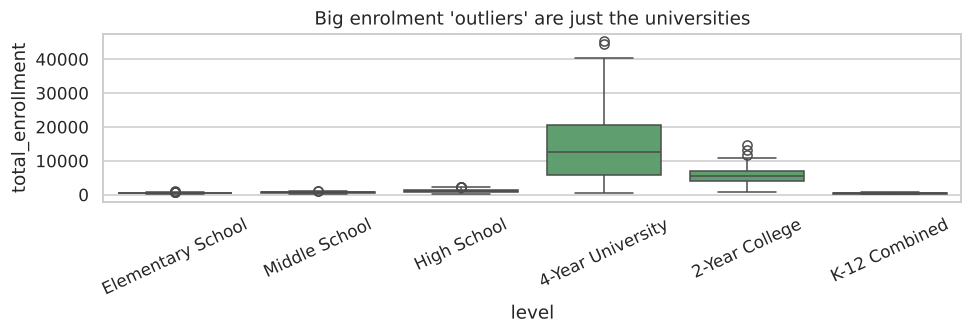

In [7]:
plt.figure(figsize=(9,3.2))
sns.boxplot(data=df, x="level", y="total_enrollment", color="#55A868")
plt.xticks(rotation=25); plt.title("Big enrolment 'outliers' are just the universities")
plt.tight_layout(); plt.show()

The enormous enrolment numbers belong to 2-year and 4-year colleges, which really do have thousands of students. These aren't errors, so I keep them.

Now the cleaning decisions themselves:

In [8]:
# Keep the test columns but set them aside — don't zero-fill, don't model on them
structural = ["avg_sat_score","avg_act_score","ap_ib_participation_pct","postsecondary_enrollment_pct"]

# Two small, honest features
df["minority_pct"] = 100 - df["racial_white_pct"]
df["is_title_i"] = df["title_i_status"].isin(["Title I Schoolwide","Title I Targeted"]).astype(int)

df.to_csv("us_education_cleaned.csv", index=False)
print("Set aside (kept, not modelled):", structural)
print("Saved cleaned data -> us_education_cleaned.csv")

Set aside (kept, not modelled): ['avg_sat_score', 'avg_act_score', 'ap_ib_participation_pct', 'postsecondary_enrollment_pct']
Saved cleaned data -> us_education_cleaned.csv


## 5 · Exploring the data

### What the key variables look like

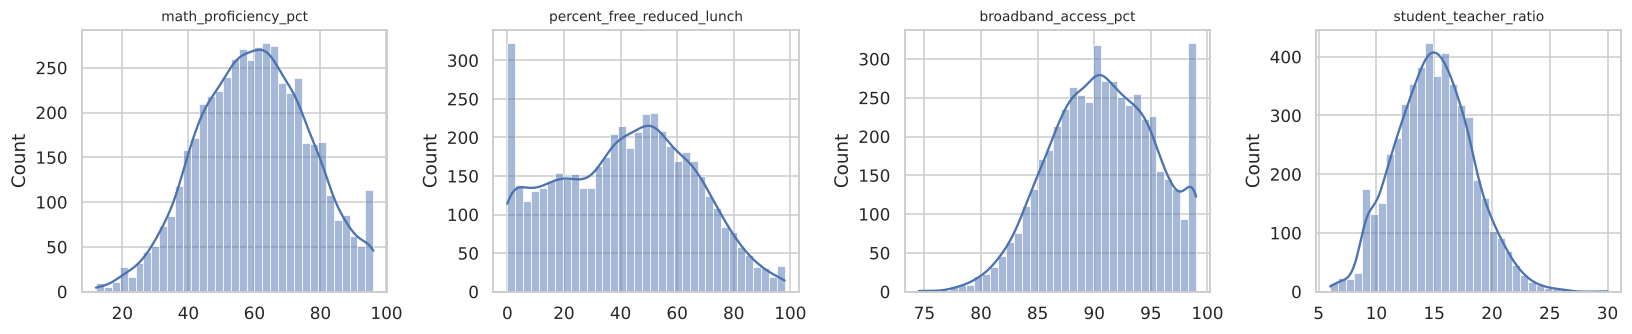

In [9]:
cols = ["math_proficiency_pct","percent_free_reduced_lunch","broadband_access_pct","student_teacher_ratio"]
fig, ax = plt.subplots(1,4, figsize=(15,3.2))
for a,c in zip(ax,cols):
    sns.histplot(df[c], kde=True, ax=a, color="#4C72B0", bins=35); a.set_title(c, fontsize=9); a.set_xlabel("")
plt.tight_layout(); plt.show()

Maths proficiency spreads widely (a standard deviation of about 16 points), so there's plenty of variation to explain. Poverty levels run the full range. Broadband sits high for most schools but with a meaningful tail.

### Which conditions track with results?

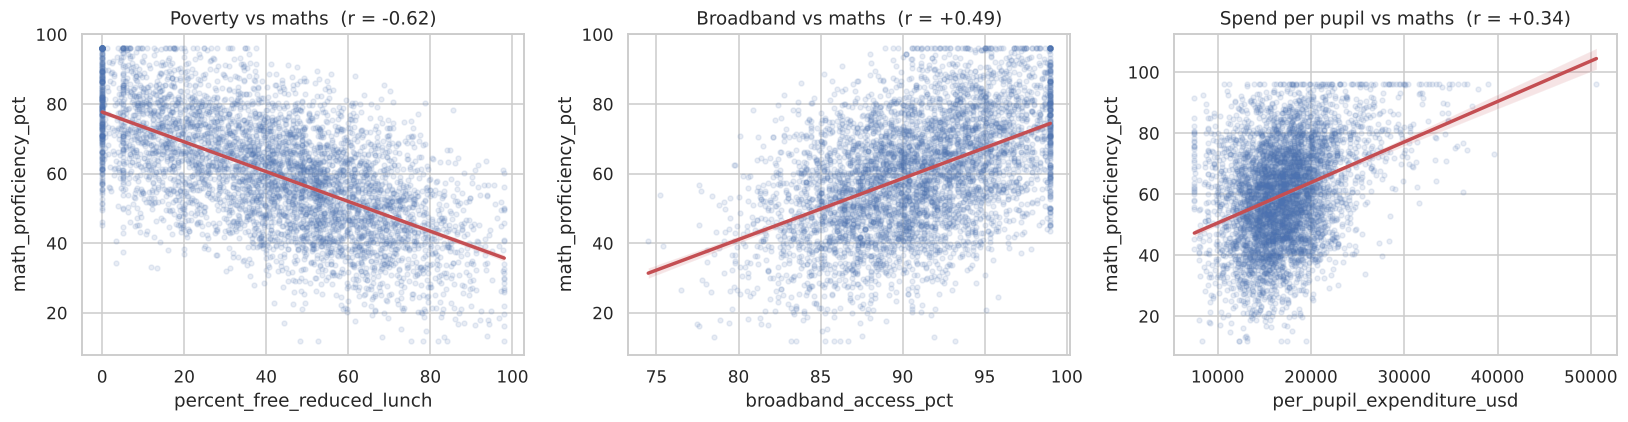

In [10]:
pairs = [("percent_free_reduced_lunch","Poverty"),("broadband_access_pct","Broadband"),
         ("per_pupil_expenditure_usd","Spend per pupil")]
fig, ax = plt.subplots(1,3, figsize=(15,4))
for a,(x,lab) in zip(ax,pairs):
    sns.regplot(data=df, x=x, y="math_proficiency_pct", ax=a,
                scatter_kws=dict(alpha=0.12,s=10), line_kws=dict(color="#C44E52"))
    r = df[[x,"math_proficiency_pct"]].corr().iloc[0,1]
    a.set_title(f"{lab} vs maths  (r = {r:+.2f})")
plt.tight_layout(); plt.show()

Two things jump out. Poverty has the strongest pull by far (r around −0.62) — the more students on free lunch, the lower the maths scores. Broadband runs the other way and is clearly positive (around +0.49). Spending nudges upward but it's weak. Money helps a little; context and connectivity help a lot.

### Results by Title I status

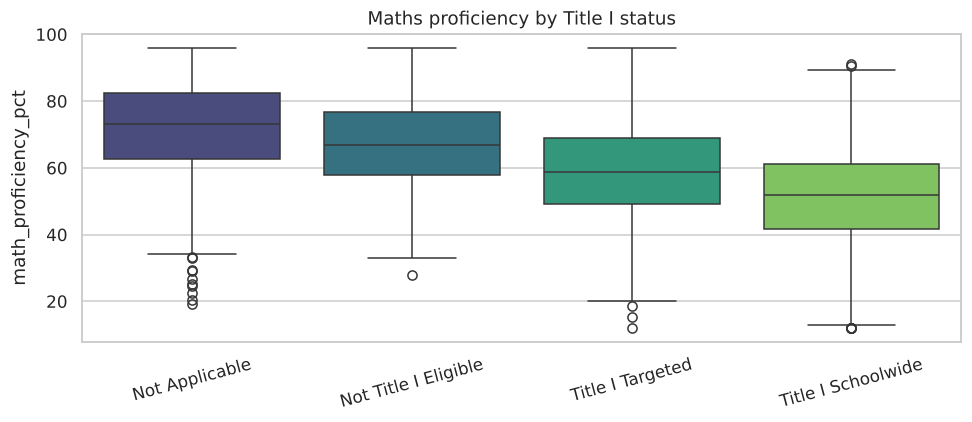

title_i_status
Not Applicable          72.4
Not Title I Eligible    67.2
Title I Targeted        58.9
Title I Schoolwide      51.7
Name: math_proficiency_pct, dtype: float64


In [11]:
order = ["Not Applicable","Not Title I Eligible","Title I Targeted","Title I Schoolwide"]
plt.figure(figsize=(9,4))
sns.boxplot(data=df, x="title_i_status", y="math_proficiency_pct", order=order, palette="viridis")
plt.xticks(rotation=15); plt.title("Maths proficiency by Title I status"); plt.xlabel("")
plt.tight_layout(); plt.show()
print(df.groupby("title_i_status")["math_proficiency_pct"].mean().round(1).reindex(order))

There's a steady slide from the non-Title-I schools down to the Title I Schoolwide ones — roughly 72% proficiency at the top against about 52% at the bottom. Title I status, which marks out concentrated poverty, cleanly separates the strong schools from the struggling ones.

### Does broadband still matter once I account for poverty?

This is the one multi-variable check worth doing. If broadband were just a proxy for wealth, its advantage would vanish inside poorer schools. It doesn't.

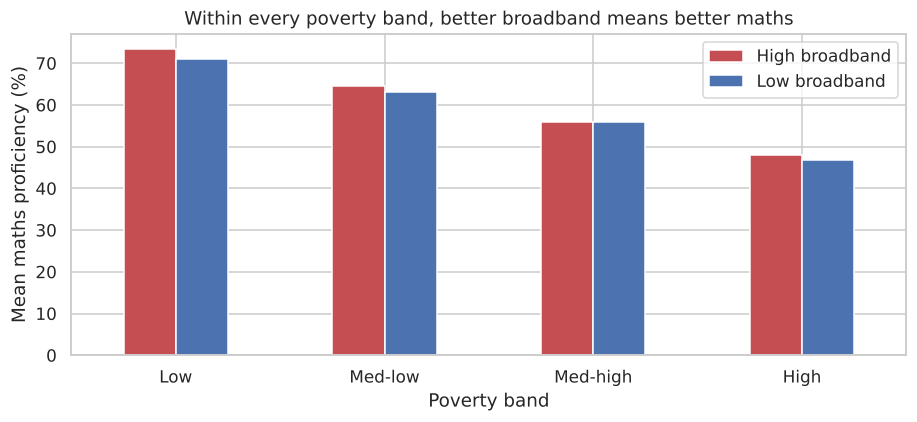

broadband_band,High broadband,Low broadband
poverty_band,,
Low,73.4,71.1
Med-low,64.5,63.1
Med-high,55.9,55.8
High,48.1,46.8


In [12]:
df["poverty_band"] = pd.qcut(df["percent_free_reduced_lunch"], 4, labels=["Low","Med-low","Med-high","High"])
df["broadband_band"] = np.where(df["broadband_access_pct"]>=df["broadband_access_pct"].median(),
                                "High broadband","Low broadband")
piv = df.pivot_table(index="poverty_band", columns="broadband_band",
                     values="math_proficiency_pct", aggfunc="mean").round(1)
piv.plot(kind="bar", figsize=(8.5,4), color=["#C44E52","#4C72B0"])
plt.title("Within every poverty band, better broadband means better maths")
plt.ylabel("Mean maths proficiency (%)"); plt.xlabel("Poverty band"); plt.xticks(rotation=0); plt.legend(title="")
plt.tight_layout(); plt.show()
piv

In each poverty band, the better-connected schools come out ahead. So broadband is carrying its own signal, not just echoing poverty. That's the sort of finding a stakeholder can act on, because connectivity is something you can fund directly.

## 6 · Testing a few of these ideas properly

Eyeballing charts is a start. Here I run three quick tests to check the patterns are real and not just noise.

In [13]:
# 1) Broadband gap — Welch t-test
hi = df.loc[df["broadband_band"]=="High broadband","math_proficiency_pct"]
lo = df.loc[df["broadband_band"]=="Low broadband","math_proficiency_pct"]
t, p = stats.ttest_ind(hi, lo, equal_var=False)
print(f"Broadband gap: high={hi.mean():.1f}%  low={lo.mean():.1f}%  (+{hi.mean()-lo.mean():.1f} pts)  p={p:.1e}")

# 2) Poverty vs maths — correlation with a confidence interval
r, pr = stats.pearsonr(df["percent_free_reduced_lunch"], df["math_proficiency_pct"])
z = np.arctanh(r); se = 1/np.sqrt(len(df)-3)
print(f"Poverty vs maths: r={r:+.2f}  95% CI [{np.tanh(z-1.96*se):.2f}, {np.tanh(z+1.96*se):.2f}]  p={pr:.1e}")

# 3) STEM vs Title I — chi-square
ct = pd.crosstab(df["title_i_status"], df["stem_certified_flag"])
chi2, pc, dof, _ = stats.chi2_contingency(ct)
print(f"STEM vs Title I: chi2={chi2:.1f}  p={pc:.2f}  -> {'linked' if pc<0.05 else 'NOT linked'}")

Broadband gap: high=66.6%  low=53.4%  (+13.2 pts)  p=3.5e-191
Poverty vs maths: r=-0.62  95% CI [-0.64, -0.61]  p=0.0e+00
STEM vs Title I: chi2=3.8  p=0.29  -> NOT linked


The first two land firmly: the broadband gap of about 13 points is miles beyond chance, and the poverty link is strong with a tight confidence interval.

The third is the interesting one. STEM certification shows **no** relationship with Title I status (p ≈ 0.29). I'll be honest about that rather than dress it up — it tells me STEM status isn't driven by the opportunity factors in this data, so I won't waste a model trying to predict it. Better to point the modelling at the outcome where there's real signal.

## 7 · Building a model for maths proficiency

I want to predict `math_proficiency_pct` from the *opportunity* conditions only — the things a stakeholder might influence. I deliberately leave out the other result columns (reading, graduation, absenteeism). Reading scores would predict maths almost perfectly, but that's just one test score explaining another. It wouldn't tell me anything about opportunity, so it stays out.

I compare a plain Linear Regression against a Random Forest.

In [14]:
num = ["total_enrollment","number_of_teachers","student_teacher_ratio","percent_free_reduced_lunch",
       "racial_white_pct","racial_black_pct","racial_hispanic_pct","racial_asian_pct",
       "special_education_pct","english_learner_pct","per_pupil_expenditure_usd",
       "federal_funding_pct","state_funding_pct","local_funding_pct","broadband_access_pct"]
cat = ["nces_locale","level","control","title_i_status"]

X = df[num+cat]; y = df["math_proficiency_pct"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=SEED)

prep = ColumnTransformer([("n", StandardScaler(), num),
                          ("c", OneHotEncoder(handle_unknown="ignore", drop="first"), cat)])

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=SEED, n_jobs=-1),
}
fitted = {}
for name, m in models.items():
    pipe = Pipeline([("prep", prep), ("model", m)]).fit(Xtr, ytr)
    fitted[name] = pipe
print(f"Trained on {len(Xtr):,} schools, testing on {len(Xte):,}.")

Trained on 4,000 schools, testing on 1,000.


## 8 · How well does it do?

I report three numbers. MAE (average error in proficiency points) is the one I lead with because anyone can understand it. I also include a "just predict the average" baseline so the model has something honest to beat.

In [15]:
rows = []
base = np.full(len(yte), ytr.mean())
rows.append(("Baseline (guess the average)", mean_absolute_error(yte,base),
             np.sqrt(mean_squared_error(yte,base)), 0.0))
for name, pipe in fitted.items():
    p = pipe.predict(Xte)
    rows.append((name, mean_absolute_error(yte,p), np.sqrt(mean_squared_error(yte,p)), r2_score(yte,p)))
scores = pd.DataFrame(rows, columns=["Model","MAE","RMSE","R2"]).set_index("Model").round(2)
scores

,MAE,RMSE,R2
Model,,,
Baseline (guess the average),13.37,16.42,0.00
Linear Regression,10.55,13.17,0.36
Random Forest,10.66,13.32,0.34


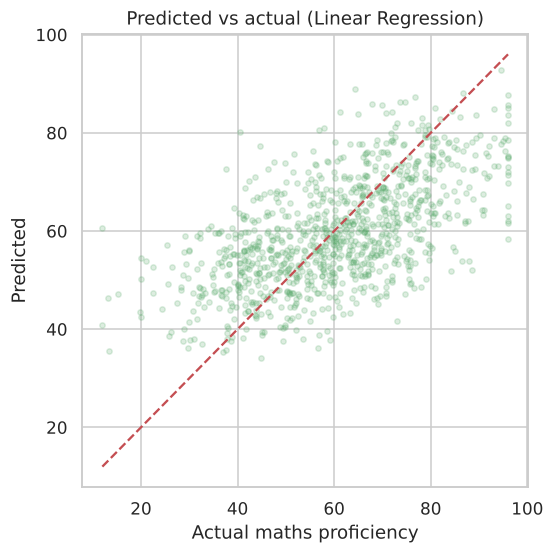

In [16]:
best = "Linear Regression"
pred = fitted[best].predict(Xte)
plt.figure(figsize=(5.2,5.2))
plt.scatter(yte, pred, alpha=0.2, s=12, color="#55A868")
plt.plot([yte.min(),yte.max()],[yte.min(),yte.max()],"--",color="#C44E52")
plt.xlabel("Actual maths proficiency"); plt.ylabel("Predicted")
plt.title("Predicted vs actual (Linear Regression)")
plt.tight_layout(); plt.show()

Both models land in the same place — an R² of about 0.35 and an average error near 10.5 points, down from 13.4 for the baseline. The forest doesn't beat the straight line, which tells me the relationships here are mostly simple and additive. So I'll keep the linear model as my main one; it's easier to read and it does the job just as well.

An R² of 0.35 isn't a disappointment, it's the honest ceiling. Opportunity conditions explain about a third of why schools differ. The rest comes from things this dataset can't see — teaching quality, leadership, curriculum, what happens at home.

## 9 · What the model picked up on

The whole point was to find the levers. Here are the strongest ones, read off the linear model's coefficients and cross-checked against the forest's feature importance.

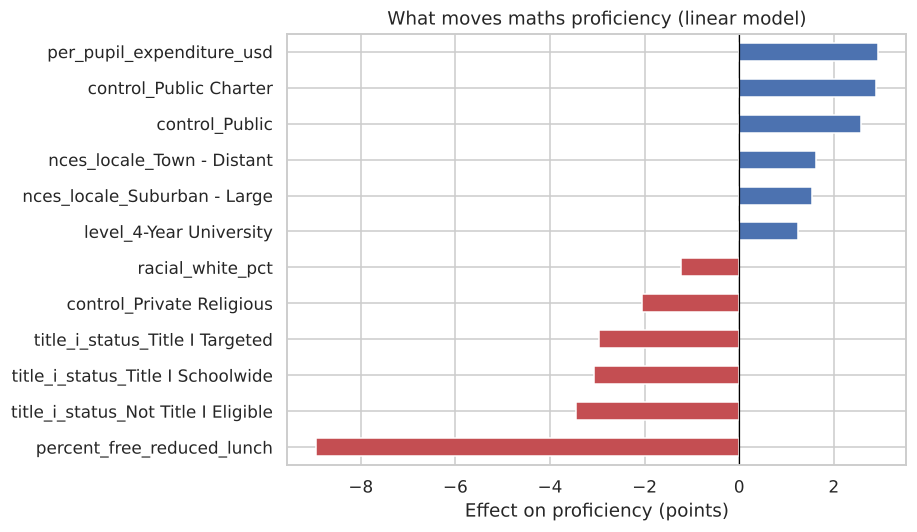

In [17]:
lin = fitted["Linear Regression"]
names = num + list(lin.named_steps["prep"].named_transformers_["c"].get_feature_names_out(cat))
coef = pd.Series(lin.named_steps["model"].coef_, index=names).sort_values()
top = pd.concat([coef.head(6), coef.tail(6)])
plt.figure(figsize=(8.5,5))
top.plot(kind="barh", color=np.where(top>0,"#4C72B0","#C44E52"))
plt.axvline(0, color="black", lw=0.8)
plt.title("What moves maths proficiency (linear model)")
plt.xlabel("Effect on proficiency (points)")
plt.tight_layout(); plt.show()

In [18]:
rf = fitted["Random Forest"]
imp = pd.Series(rf.named_steps["model"].feature_importances_, index=names).sort_values(ascending=False).head(8)
print("Random Forest's most important features:")
print(imp.round(3))

Random Forest's most important features:
percent_free_reduced_lunch    0.437
per_pupil_expenditure_usd     0.084
special_education_pct         0.042
student_teacher_ratio         0.041
broadband_access_pct          0.039
racial_black_pct              0.038
racial_asian_pct              0.038
racial_hispanic_pct           0.035
dtype: float64


Both models tell the same story. Poverty does the heavy lifting — it's the single biggest factor pulling scores down. Broadband is the strongest thing pushing them up. Title I Schoolwide status carries a negative weight even after demographics, because it marks the schools where need is most concentrated. Spending and class size barely register once those are in the mix.

One caveat I won't skip over: these are *associations*. I can say connected schools do better, even among equally poor ones. I can't say that installing broadband tomorrow would lift scores — that would need a proper trial, not a snapshot.

## 10 · What this means, and what to do about it

**Three things I'm confident about**

1. **Poverty is the main fault line.** It correlates −0.62 with maths and tops every model. High-poverty (Title I Schoolwide) schools average around 52% proficiency against 72% for the better-off ones.
2. **Broadband is a real, separate lever.** The 13-point gap holds inside every poverty band, so it's not just standing in for wealth. And unlike "poverty," it's something you can fund.
3. **STEM certification is a red herring here.** It has no link to Title I status or the resource picture, so it shouldn't be used to decide who gets help.

**What I'd tell the stakeholder**

| Finding | What to do | Why it helps | The catch |
|---|---|---|---|
| Poverty drives the biggest gap | Weight funding towards high-poverty / Title I Schoolwide schools, paired with wrap-around support | Targets the largest gap in the data | Money alone was weak — tie it to programmes that work |
| Broadband carries its own signal | Fund connectivity (devices + home access) for the least-connected schools | Plausibly lifts results where gaps are widest | It's an association — pilot it and measure before and after |
| Low-performing schools are easy to spot | Use poverty + connectivity as a simple triage filter for grants | Puts limited money where it counts | Refresh as new data comes in |
| STEM flag tells us nothing here | Don't use STEM status for targeting; find out how it's actually awarded first | Avoids acting on noise | The data doesn't show the certification rules |

## 11 · Limits and where I'd go next

This is a single snapshot, so every result is a correlation, not proof of cause. The model explains about a third of the variation, which leaves a lot sitting in factors the data doesn't capture. And the test-score columns only exist for secondary schools, so I kept the model to conditions shared by every school.

With more time I'd bring in neighbourhood income data to separate the school's effect from its community's, get detail on *how* money is spent rather than just how much, and — if the budget allowed — design a small connectivity trial to test whether broadband genuinely moves the needle.

## 12 · A short reflection

The thing I'm most pleased with is a decision I almost got wrong. I started out meaning to predict STEM certification, then the chi-square test came back flat and I had to admit there was nothing there to predict. Switching to maths proficiency, where the signal was obvious, saved the project. The trickiest part was resisting the urge to throw reading scores into the model — it would have pushed the R² up and taught me nothing. Knowing what to leave out turned out to matter as much as knowing what to put in.